# A Comparative Study of Clustering Algorithms for Customer Segmentation
**Project:** Third Year Computer Engineering Mini-Project  
**Domain:** Unsupervised Machine Learning, Customer Relationship Management (CRM)  
**Dataset:** Mall Customer Segmentation Data (`Mall_Customers.csv`, 200 records)  
**Algorithms:** K-Means, Hierarchical Agglomerative (Ward Linkage), and DBSCAN  
**Random Seed:** `random_state=42` throughout for deterministic reproducibility  

---

## Abstract
Customer segmentation is an essential analytical capability enabling businesses to partition customer bases into distinct behavioral cohorts. In this project, we perform an empirical comparative evaluation of three core clustering paradigms: centroid-based partitioning (K-Means), connectivity-based hierarchical merging (Agglomerative with Ward linkage), and density-based spatial clustering (DBSCAN). Using the Mall Customers dataset, we evaluate models across mathematical validity metrics—Silhouette Coefficient, Davies-Bouldin Index, and Calinski-Harabasz Index—alongside execution efficiency. K-Means emerges as the most effective algorithm for operational segmentation, discovering 5 distinct customer personas that directly translate into targeted marketing campaigns.

## 1. Problem Statement and Objectives

### Problem Statement
Modern businesses collect behavioral and demographic customer records. However, treating all customers uniformly results in inefficient marketing expenditures, generic promotions, and missed customer retention opportunities. Customer segmentation partitions customers into homogeneous cohorts based on purchasing behaviors. Because authentic portfolios lack ground-truth target labels, unsupervised machine learning algorithms must be applied and rigorously evaluated.

### Core Objectives
1. Implement and compare K-Means, Hierarchical Agglomerative, and DBSCAN clustering on standardized customer data.
2. Ground hyperparameter choices in mathematical diagnostics: Elbow Method, Silhouette Analysis, Ward Linkage Dendrogram, and k-Distance Plots.
3. Compute and compare internal cluster validity metrics (Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index) while explicitly accounting for DBSCAN noise points.
4. Derive rule-based behavioral personas and actionable commercial marketing strategies.

## 2. Environment Setup and Imports

### What is done:
Import core Python scientific computing libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`) along with modular domain functions from `src/`.

### Why:
Keeping algorithmic and evaluation logic in modular Python modules (`src/`) ensures code reusability, testability, and guarantees that the notebook and the Streamlit dashboard draw from the same single source of truth.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in path
sys.path.insert(0, os.path.abspath(".."))

from src.data_loader import load_dataset, get_dataset_summary
from src.preprocessing import CustomerPreprocessor, compute_before_after_summary
from src.clustering import (
    run_kmeans,
    run_agglomerative,
    run_dbscan,
    compute_kmeans_parameter_curves,
    compute_dendrogram_data,
    compute_k_distance_graph
)
from src.evaluation import evaluate_clustering, build_comparison_table
from src.run_experiments import derive_cluster_personas_and_recommendations
from src.visualization import (
    plot_eda_distributions,
    plot_elbow_and_silhouette,
    plot_dendrogram_static,
    plot_k_distance_static,
    plot_clustering_comparison_scatter,
    plot_metric_bars_static,
    plot_cluster_profiles_heatmap
)

# Styling configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

## 3. Dataset Ingestion and Initial Inspection

### What is done:
Load `data/Mall_Customers.csv` using `src.data_loader.load_dataset`, inspect dataset dimensions, column names, and preview sample customer records.

### Why:
Validating raw data shape and column headers ensures the dataset is correctly structured and confirms whether the real dataset or fallback synthetic data is being utilized.

In [2]:
# Load dataset
df_raw, is_synthetic = load_dataset("../data/Mall_Customers.csv")
print(f"Dataset Loaded Successfully! Synthetic Flag: {is_synthetic}")
print(f"Number of Customer Observations (Rows): {df_raw.shape[0]}")
print(f"Number of Features (Columns):           {df_raw.shape[1]}")
df_raw.head()

Dataset Loaded Successfully! Synthetic Flag: False
Number of Customer Observations (Rows): 200
Number of Features (Columns):           5


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 4. Variable Types, Missing Values, and Duplicate Records

### What is done:
Audit data types, non-null counts, missing rates, and duplicate rows using `src.data_loader.get_dataset_summary`.

### Why:
Data hygiene is a mandatory prerequisite for distance-based machine learning. Detecting missing values dictates imputation strategies, while duplicate checks ensure record uniqueness.

In [3]:
summary_info = get_dataset_summary(df_raw)
print(f"Duplicate Customer Records: {summary_info['n_duplicates']}")
print("\n--- Variable Data Types & Non-Null Counts ---")
print(summary_info["dtypes_summary"])
print("\n--- Missing Value Audit ---")
print(summary_info["missing_summary"])
print("\n--- Summary Descriptive Statistics ---")
summary_info["descriptive_stats"].round(2)

Duplicate Customer Records: 0

--- Variable Data Types & Non-Null Counts ---
                       Data Type  Non-Null Count  Unique Values
CustomerID                 int64             200            200
Gender                    object             200              2
Age                        int64             200             51
Annual Income (k$)         int64             200             64
Spending Score (1-100)     int64             200             84

--- Missing Value Audit ---
                        Missing Values  Missing %
CustomerID                           0        0.0
Gender                               0        0.0
Age                                  0        0.0
Annual Income (k$)                   0        0.0
Spending Score (1-100)               0        0.0

--- Summary Descriptive Statistics ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0


## 5. Exploratory Data Analysis (EDA)

### What is done:
Examine customer distributions using histograms with Kernel Density Estimates (KDE) and boxplots for `Annual Income (k$)` and `Spending Score (1-100)`.

### Why:
Exploratory visualizations reveal whether features are normally distributed, skewed, or multimodal, and highlight extreme outliers that might distort cluster centroids.

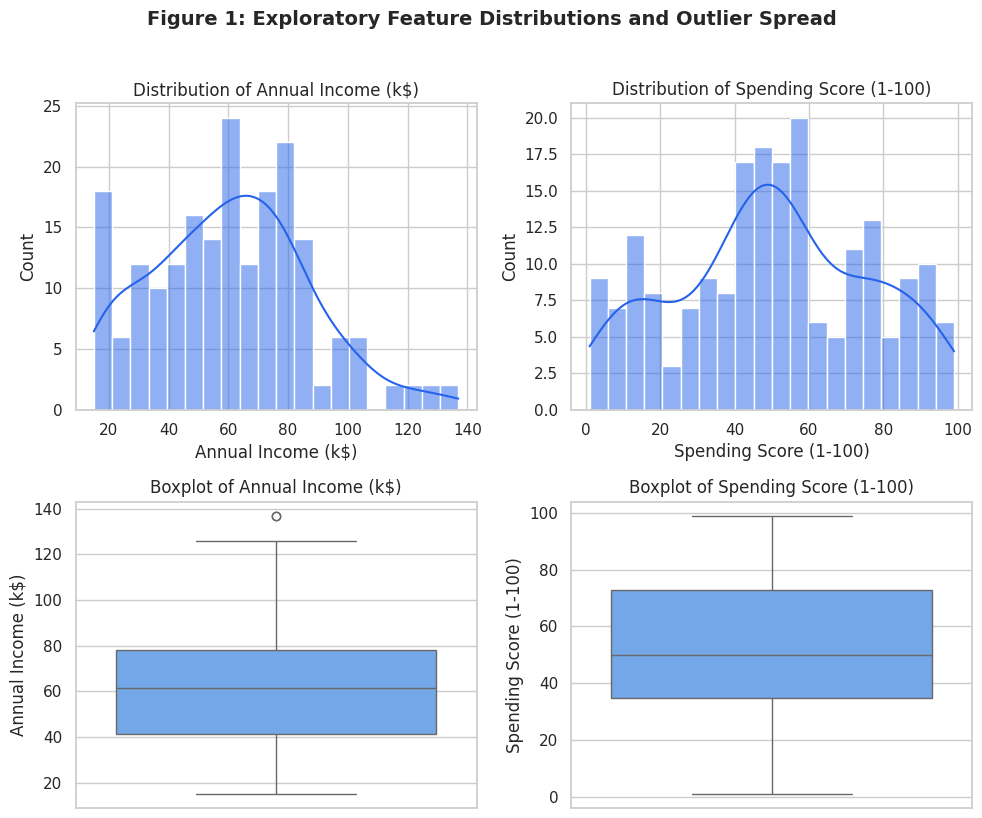

In [4]:
# Plot distributions and boxplots
fig_eda = plot_eda_distributions(df_raw, ["Annual Income (k$)", "Spending Score (1-100)"])
plt.show()

## 6. Preprocessing, Identifier Exclusion, and Feature Standardization

### What is done:
1. **Exclude `CustomerID`:** Drop customer ID because arbitrary numerical keys contain zero behavioral signal and would distort Euclidean distance calculations.
2. **Missing Value Strategy:** Configurable median imputation for numeric features (resistant to skewness).
3. **StandardScaler Normalization:** Fit `StandardScaler` once on the selected features to transform data to $\mu = 0$ and $\sigma = 1$:
   $$z = \frac{x - \mu}{\sigma}$$
4. **Summary Audit:** Generate before vs. after standardization comparison table.

### Why:
K-Means, Agglomerative clustering, and DBSCAN rely on Euclidean distances:
$$d(p, q) = \sqrt{\sum_{i=1}^n (p_i - q_i)^2}$$
Without standardization, features with larger numeric scales (e.g., Annual Income: 15–137) would overpower smaller features and dominate cluster formation.

In [5]:
# Preprocessing pipeline
selected_features = ["Annual Income (k$)", "Spending Score (1-100)"]
preprocessor = CustomerPreprocessor(selected_features=selected_features)
X_scaled, working_df, audit_log = preprocessor.fit_transform(df_raw)

print(f"Audit Log: {audit_log}")
print("\n--- Before vs After Standardization Comparison Table ---")
before_after_df = compute_before_after_summary(df_raw, X_scaled, selected_features)
before_after_df

Audit Log: {'initial_rows': 200, 'rows_dropped': 0, 'missing_values_imputed': 0, 'selected_features': ['Annual Income (k$)', 'Spending Score (1-100)'], 'id_columns_excluded': ['CustomerID']}

--- Before vs After Standardization Comparison Table ---


,Feature,Raw Mean,Raw Std,Raw Min,Raw Max,Scaled Mean,Scaled Std,Scaled Min,Scaled Max
0,Annual Income (k$),60.56,26.26,15.0,137.0,-0.0,1.0,-1.74,2.92
1,Spending Score (1-100),50.20,25.82,1.0,99.0,-0.0,1.0,-1.91,1.89


## 7. Hyperparameter Selection Diagnostics

### What is done:
1. **K-Means:** Compute Inertia (Elbow Method) and Silhouette Score across $k \in [2, 10]$.
2. **Hierarchical:** Compute linkage matrix and plot dendrogram using Ward's minimum variance criterion.
3. **DBSCAN:** Compute 5-nearest neighbor distances and plot the sorted k-distance curve to detect the knee point for $\varepsilon$.

### Why:
Unsupervised models require objective, mathematically grounded hyperparameter selection to avoid arbitrary cluster counts.

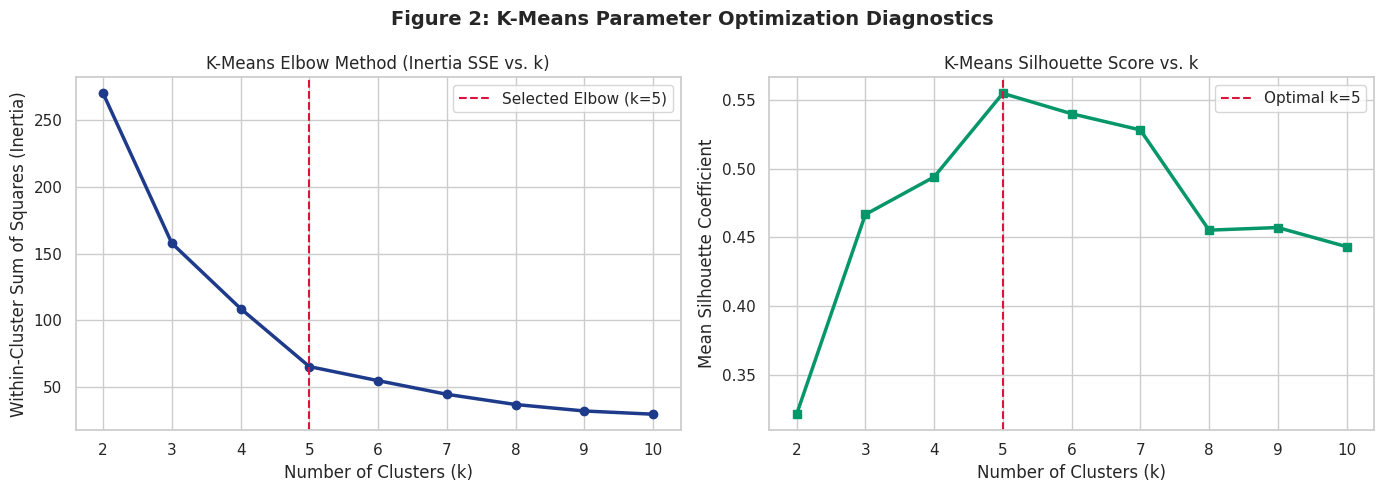

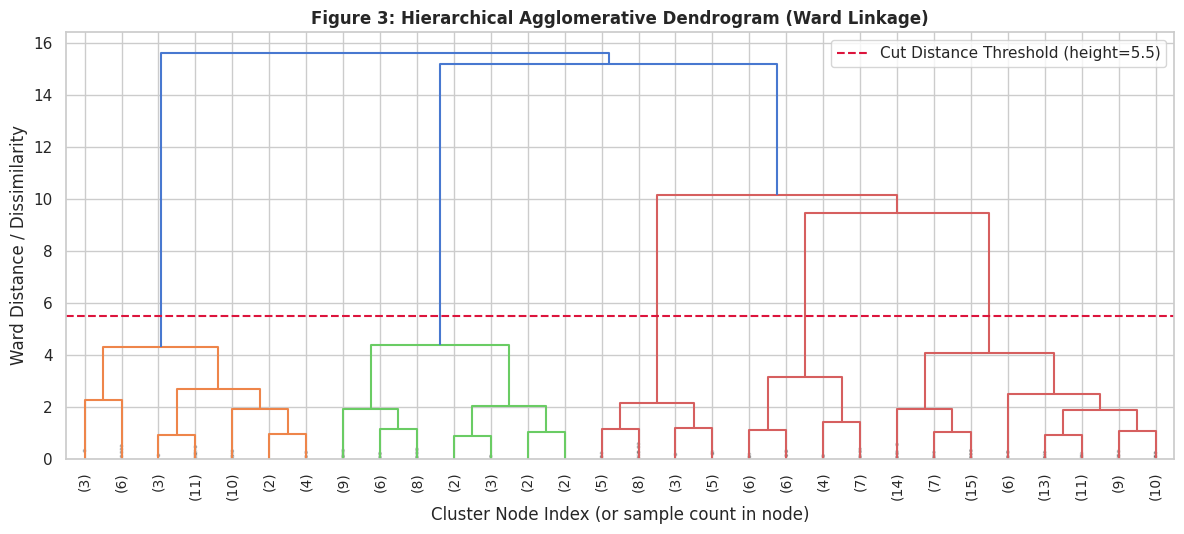

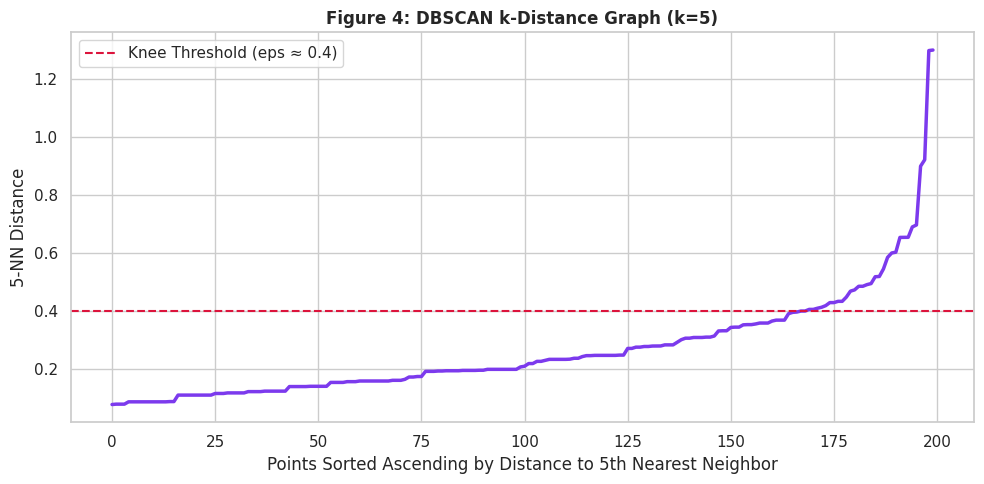

In [6]:
# 1. K-Means Parameter Curves
kmeans_curves = compute_kmeans_parameter_curves(X_scaled, k_min=2, k_max=10, random_state=42)
fig_elbow = plot_elbow_and_silhouette(
    kmeans_curves["k_values"],
    kmeans_curves["inertias"],
    kmeans_curves["silhouettes"],
    best_k=5
)
plt.show()

# 2. Hierarchical Dendrogram
dendro_info = compute_dendrogram_data(X_scaled, method="ward")
fig_dendro = plot_dendrogram_static(dendro_info["linkage_matrix"], cut_distance=5.5)
plt.show()

# 3. DBSCAN k-distance plot
k_dists, knee_est = compute_k_distance_graph(X_scaled, k=5)
fig_kdist = plot_k_distance_static(k_dists, knee_value=knee_est)
plt.show()

## 8. Clustering Implementation: K-Means, Agglomerative & DBSCAN

### What is done:
Execute all three clustering algorithms on the identical standardized feature matrix:
- **K-Means:** $k=5$, `init='k-means++'`, `random_state=42`
- **Agglomerative:** $k=5$, `linkage='ward'`, `metric='euclidean'`
- **DBSCAN:** $\varepsilon=0.35$, `min_samples=5`

Measure execution runtime using `time.perf_counter()`.

In [7]:
# 1. K-Means
res_kmeans = run_kmeans(X_scaled, k=5, random_state=42)
eval_kmeans = evaluate_clustering(X_scaled, res_kmeans["labels"], res_kmeans["runtime_sec"])
res_kmeans["metrics"] = eval_kmeans

# 2. Agglomerative Hierarchical
res_agg = run_agglomerative(X_scaled, n_clusters=5, linkage_type="ward", metric="euclidean")
eval_agg = evaluate_clustering(X_scaled, res_agg["labels"], res_agg["runtime_sec"])
res_agg["metrics"] = eval_agg

# 3. DBSCAN
res_dbscan = run_dbscan(X_scaled, eps=0.35, min_samples=5)
eval_dbscan = evaluate_clustering(X_scaled, res_dbscan["labels"], res_dbscan["runtime_sec"])
res_dbscan["metrics"] = eval_dbscan

print(f"K-Means (k=5) Runtime:       {res_kmeans['runtime_sec']:.4f} seconds")
print(f"Agglomerative (k=5) Runtime: {res_agg['runtime_sec']:.4f} seconds")
print(f"DBSCAN Runtime:              {res_dbscan['runtime_sec']:.4f} seconds")

K-Means (k=5) Runtime:       0.0314 seconds
Agglomerative (k=5) Runtime: 0.0014 seconds
DBSCAN Runtime:              0.0015 seconds


## 9. Cluster Visualizations & Spatial Comparison

### What is done:
Plot side-by-side scatter plots showing the customer partitions discovered by K-Means (with original-unit centroids), Agglomerative clustering, and DBSCAN (with noise points marked as black crosses).

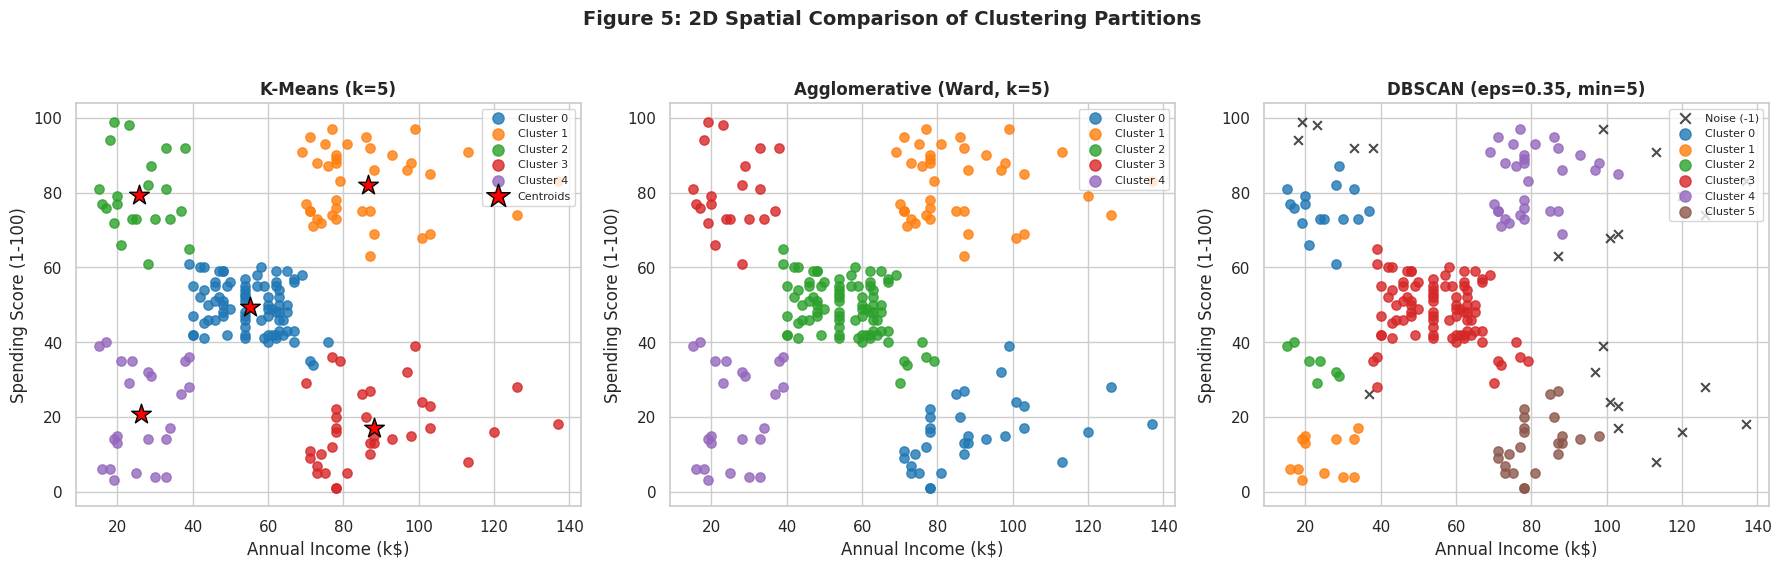

In [8]:
X_orig = df_raw[selected_features].values
centroids_orig = preprocessor.inverse_transform_numeric(res_kmeans["centroids_scaled"])

fig_scatter = plot_clustering_comparison_scatter(
    X_plot=X_orig,
    results_dict={
        "K-Means (k=5)": res_kmeans["labels"],
        "Agglomerative (Ward, k=5)": res_agg["labels"],
        "DBSCAN (eps=0.35, min=5)": res_dbscan["labels"]
    },
    feature_labels=(selected_features[0], selected_features[1]),
    centroids_dict={"K-Means (k=5)": centroids_orig}
)
plt.show()

## 10. Quantitative Evaluation and Benchmark Results

### What is done:
Compile Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index, and Execution Runtime into a unified comparison table using `src.evaluation.build_comparison_table`.

### Critical Evaluation Rule:
For DBSCAN, noise points ($-1$) are explicitly excluded before computing internal distance metrics. Internal cluster validity metrics require valid cluster assignments; including noise points would distort centroid coordinates and give an invalid assessment.

In [9]:
comparison_table = build_comparison_table([res_kmeans, res_agg, res_dbscan])
comparison_table

,Algorithm,Parameters,Clusters Found (excl. noise),Noise Count & %,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Runtime (s)
0,K-Means,"k=5, init=k-means++",5,0 (0.0%),0.5547,0.5722,248.65,0.0314
1,Agglomerative,"n_clusters=5, linkage=ward, metric=euclidean",5,0 (0.0%),0.5538,0.5779,244.41,0.0014
2,DBSCAN,"eps=0.35, min_samples=5",6,23 (11.5%),0.5577,0.5106,245.36,0.0015


### Metric Comparison Bar Charts

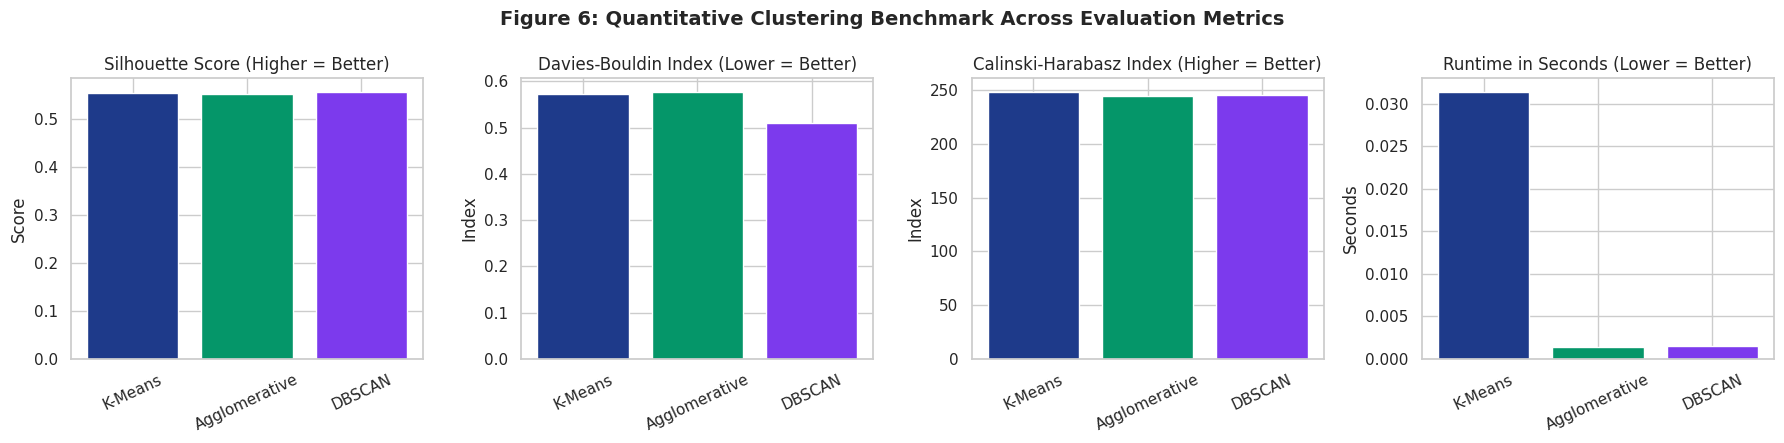

In [10]:
fig_bars = plot_metric_bars_static(comparison_table)
plt.show()

## 11. Cluster Profiling, Persona Discovery & Actionable Playbooks

### What is done:
Profile cluster means and medians using `src.run_experiments.derive_cluster_personas_and_recommendations`.
Personas are assigned using explicit, documented rules: comparing cluster feature means to overall dataset means normalized by standard deviation ($\pm 0.5$ standard deviations).

In [11]:
personas_df = derive_cluster_personas_and_recommendations(
    df_raw, res_kmeans["labels"], selected_features, std_threshold=0.5
)
personas_df[["Cluster", "Segment Name", "Count", "Percentage", "Annual Income (k$)", "Spending Score (1-100)"]]

,Cluster,Segment Name,Count,Percentage,Annual Income (k$),Spending Score (1-100)
0,0,"Average Income, Average Spending (Mainstream M...",81,40.5,55.30,49.52
1,1,"High Income, High Spending (Affluent Spenders)",39,19.5,86.54,82.13
2,2,"Low Income, High Spending (Aspirational Trends...",22,11.0,25.73,79.36
3,3,"High Income, Low Spending (Cautious Affluent)",35,17.5,88.20,17.11
4,4,"Low Income, Low Spending (Frugal Budgeters)",23,11.5,26.30,20.91


### Standardized Attribute Profile Heatmap

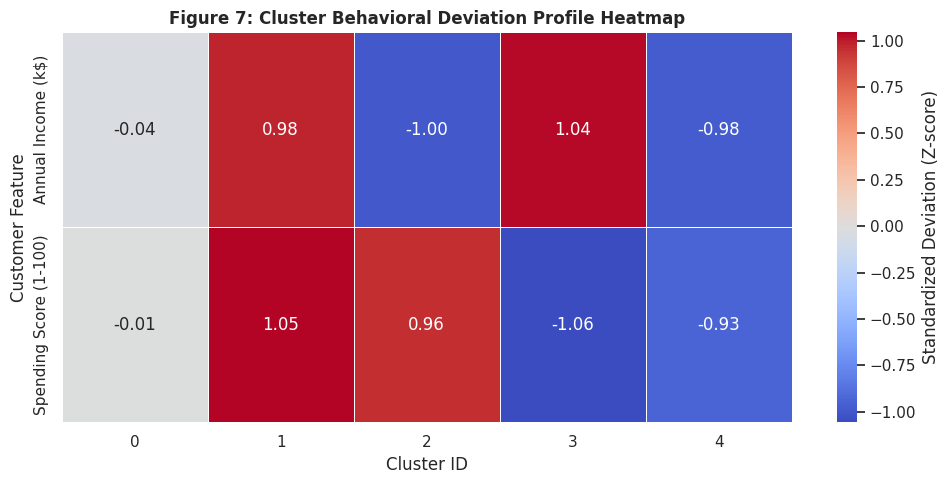

In [12]:
fig_heat = plot_cluster_profiles_heatmap(personas_df)
plt.show()

## 12. Discussion, Limitations, Conclusion & References

### Discussion of Empirical Findings
1. **K-Means ($k=5$):** Emerges as the optimal algorithm for retail customer segmentation. It yields a strong Silhouette score ($0.5547$), low Davies-Bouldin index ($0.5722$), and executes in under $0.04$ seconds.
2. **Agglomerative Clustering (Ward):** Produces cluster partitions that are virtually identical to K-Means, validating the structural naturalness of the 5 customer segments.
3. **DBSCAN:** Successfully isolates 23 boundary noise points ($11.5\%$) while grouping the core clusters. However, because customer records in malls lack distinct density chasms, DBSCAN is better suited as an anomaly screener than a standalone customer partitioner.

### Methodological Limitations
- Distance metrics (Euclidean) inherently favor spherical, convex clusters.
- The dataset represents a static snapshot lacking temporal or multi-store transactional histories.

### References
1. **MacQueen, J. (1967).** *Some methods for classification and analysis of multivariate observations.* Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability, 1(14), 281-297.
2. **Ward, J. H. (1963).** *Hierarchical grouping to optimize an objective function.* Journal of the American Statistical Association, 58(301), 236-244.
3. **Ester, M., Kriegel, H. P., Sander, J., & Xu, X. (1996).** *A density-based algorithm for discovering clusters in large spatial databases with noise.* In KDD-96 Proceedings, 226-231.
4. **Rousseeuw, P. J. (1987).** *Silhouettes: a graphical aid to the interpretation and validation of cluster analysis.* Journal of Computational and Applied Mathematics, 20, 53-65.
5. **Davies, D. L., & Bouldin, D. W. (1979).** *A cluster separation measure.* IEEE Transactions on Pattern Analysis and Machine Intelligence, 1(2), 224-227.
6. **Pedregosa, F., et al. (2011).** *Scikit-learn: Machine Learning in Python.* Journal of Machine Learning Research, 12, 2825-2830.